# Notebook 02 — Modeling and Evaluation
**Task:** predict Remaining Useful Life (cycles) of aircraft engines (NASA C-MAPSS FD001).

**Plan**
1. Load the cleaned data (from Notebook 01) and define features, target and engine groups.
2. Split the engines with a fixed random seed and compare four models.
3. Compare the models with grouped 5-fold cross-validation.
4. Tune Ridge, Random Forest and Gradient Boosting.
5. Evaluate every final model on the **official NASA test set** (the last observed cycle of 100 unseen engines).
6. Save all models (each one is a pipeline that includes its own preprocessing).

All scaling is done *inside* the pipelines, so nothing is fitted before splitting (no data leakage).

## 1. Load data and define features, target and groups

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV, cross_validate

sys.path.append("..")
from Helper.helper import load_cmapss, last_cycle_rows, evaluate, MODEL_FILES, RUL_CAP

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
IMAGES = Path("../Images")
MODELS_DIR = Path("../Models")
MODELS_DIR.mkdir(exist_ok=True)

df = pd.read_csv("../Data/Cleaned/train_FD001_cleaned.csv")

X = df.drop(columns=["RUL", "engine_id"])     # engine_id identifies the engine, it is not a feature
y = df["RUL"]
groups = df["engine_id"]

print("Features:", X.shape[1], "| Rows:", len(X), "| Engines:", groups.nunique())
print(list(X.columns))

Features: 18 | Rows: 20631 | Engines: 100
['cycle', 'setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


**Why engines are grouped.** Rows from the same engine are strongly dependent. If one engine appeared in both the training and the validation part, the model would see almost the same data twice and the scores would look better than they really are. Every split below therefore keeps all rows of an engine together.

## 2. Model definitions

In [2]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0)),
    ]),
    "Random Forest": Pipeline([
        ("model", RandomForestRegressor(n_estimators=100, min_samples_leaf=2,
                                        random_state=SEED, n_jobs=-1)),
    ]),
    "Gradient Boosting": Pipeline([
        ("model", GradientBoostingRegressor(n_estimators=100, learning_rate=0.1,
                                            max_depth=3, random_state=SEED)),
    ]),
}
list(models)

['Linear Regression', 'Ridge', 'Random Forest', 'Gradient Boosting']

The two linear models get a `StandardScaler` because their coefficients depend on feature scale. The two tree-based models split on thresholds, so scaling does not change them and is skipped.

## 3. Train / validation split (fixed seed) and baseline comparison
We hold out 20% of the **engines** (20 engines) as a validation set, using `random_state=42`.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(splitter.split(X, y, groups))

X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
print("Train engines:", groups.iloc[train_idx].nunique(), "| Validation engines:", groups.iloc[val_idx].nunique())
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[val_idx]))

rows = []
for name, model in models.items():
    m = clone(model).fit(X_tr, y_tr)
    rows.append({"Model": name, **evaluate(y_val, m.predict(X_val))})

holdout_df = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
holdout_df.round(3)

Train engines: 80 | Validation engines: 20


,Model,MAE,RMSE,R²
0,Gradient Boosting,22.693,29.756,0.795
1,Random Forest,23.843,31.428,0.771
2,Linear Regression,25.155,31.656,0.768
3,Ridge,25.155,31.656,0.768


## 4. Grouped 5-fold cross-validation

In [4]:
cv = GroupKFold(n_splits=5)
scoring = {"MAE": "neg_mean_absolute_error",
           "RMSE": "neg_root_mean_squared_error",
           "R2": "r2"}

rows = []
for name, model in models.items():
    s = cross_validate(model, X, y, groups=groups, cv=cv, scoring=scoring, n_jobs=-1, error_score="raise")
    rows.append({
        "Model": name,
        "MAE": -s["test_MAE"].mean(),
        "RMSE": -s["test_RMSE"].mean(),
        "R²": s["test_R2"].mean(),
        "RMSE std": s["test_RMSE"].std(),
    })

cv_df = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
cv_df.round(3)

,Model,MAE,RMSE,R²,RMSE std
0,Gradient Boosting,26.481,37.316,0.706,1.767
1,Random Forest,26.768,38.075,0.694,1.522
2,Ridge,31.159,40.556,0.652,3.457
3,Linear Regression,31.159,40.556,0.652,3.457


**Conclusion.** Gradient Boosting is best in cross-validation (RMSE 37.3, R² 0.706), followed closely by Random Forest (RMSE 38.1). Both tree-based models clearly beat the linear models (RMSE 40.6), which confirms the non-linear relationship we saw in Notebook 01. Ridge with `alpha=1` is identical to Linear Regression because 18 standardised features and 20,000 rows leave almost nothing to shrink. Note that the single 20-engine split in section 3 gave a more optimistic R² (0.795 for Gradient Boosting) than the 5-fold average (0.706): one split depends on which engines happen to be in it, which is why we rely on cross-validation for model selection.

## 5. Hyperparameter tuning (grouped cross-validation)
Three models are tuned with `GridSearchCV`. The best setting is chosen by mean validation **RMSE** and the grouped folds are the same as above.

In [5]:
param_grids = {
    "Ridge": {"model__alpha": [0.1, 1, 10, 100, 1000]},
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [10, None],
        "model__min_samples_leaf": [2, 5, 10],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3, 4],
    },
}

searches = {}
tuning_rows = []
for name, grid in param_grids.items():
    print("Tuning:", name)
    search = GridSearchCV(models[name], grid, scoring=scoring, refit="RMSE",
                          cv=cv, n_jobs=-1, error_score="raise")
    search.fit(X, y, groups=groups)
    searches[name] = search
    best = search.best_index_
    tuning_rows.append({
        "Model": name,
        "Best parameters": search.best_params_,
        "CV MAE": -search.cv_results_["mean_test_MAE"][best],
        "CV RMSE": -search.cv_results_["mean_test_RMSE"][best],
        "CV R²": search.cv_results_["mean_test_R2"][best],
    })

tuning_df = pd.DataFrame(tuning_rows)
pd.set_option("display.max_colwidth", None)
tuning_df.round(3)

Tuning: Ridge


Tuning: Random Forest


Tuning: Gradient Boosting


,Model,Best parameters,CV MAE,CV RMSE,CV R²
0,Ridge,{'model__alpha': 100},31.152,40.555,0.652
1,Random Forest,"{'model__max_depth': 10, 'model__min_samples_leaf': 10, 'model__n_estimators': 200}",26.434,37.543,0.703
2,Gradient Boosting,"{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200}",26.541,37.236,0.708


**Conclusion.** Tuning gave small gains: Gradient Boosting improved its CV RMSE from 37.32 to 37.24, Random Forest from 38.08 to 37.54, and Ridge hardly changed (40.56 → 40.55 with `alpha=100`). The best Gradient Boosting setting is shallow (`max_depth=2`) with 200 slow trees (`learning_rate=0.05`), and the best Random Forest uses large leaves (`min_samples_leaf=10`). In both cases simpler trees generalise better to new engines. After tuning, Gradient Boosting still has the lowest CV RMSE and is the leading candidate.

## 6. Official test set
NASA provides separate test engines that stop *before* failure and a file with the true RUL at their last observed cycle. As in the NASA protocol, we predict from the **last observed row of each of the 100 test engines**. This data was never used for training or tuning.

In [6]:
test_df = load_cmapss("../Data/Original/test_FD001.txt")
y_test = pd.read_csv("../Data/Original/RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])["RUL"]

test_last = last_cycle_rows(test_df)
X_test = test_last[X.columns].copy()

assert len(X_test) == len(y_test) == 100
print("Test engines:", len(X_test))
X_test.head()

Test engines: 100


,cycle,setting_1,setting_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,31,-0.0006,0.0004,642.58,1581.22,1398.91,21.61,554.42,2388.08,9056.40,47.23,521.79,2388.06,8130.11,8.4024,393,38.81,23.3552
1,49,0.0018,-0.0001,642.55,1586.59,1410.83,21.61,553.52,2388.10,9044.77,47.67,521.74,2388.09,8126.90,8.4505,391,38.81,23.2618
2,126,-0.0016,0.0004,642.88,1589.75,1418.89,21.61,552.59,2388.16,9049.26,47.88,520.83,2388.14,8131.46,8.4119,395,38.93,23.2740
3,106,0.0012,0.0004,642.78,1594.53,1406.88,21.61,552.64,2388.13,9051.30,47.65,521.88,2388.11,8133.64,8.4634,395,38.58,23.2581
4,98,-0.0013,-0.0004,642.27,1589.94,1419.36,21.61,553.29,2388.10,9053.99,47.46,521.00,2388.15,8125.74,8.4362,394,38.75,23.4117


## 7. Final models: fit on all training engines and evaluate on the test set

In [7]:
final_models = {name: clone(model) for name, model in models.items()}
for name, search in searches.items():
    final_models[name] = clone(search.best_estimator_)      # tuned settings, refit below on all data

test_predictions, rows = {}, []
for name, model in final_models.items():
    model.fit(X, y)
    pred = model.predict(X_test)
    test_predictions[name] = pred
    rows.append({"Model": name, **evaluate(y_test, pred)})

test_results_df = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
test_results_df.round(3)

,Model,MAE,RMSE,R²
0,Gradient Boosting,18.831,25.226,0.632
1,Random Forest,18.969,25.273,0.630
2,Ridge,25.930,31.211,0.436
3,Linear Regression,25.975,31.250,0.434


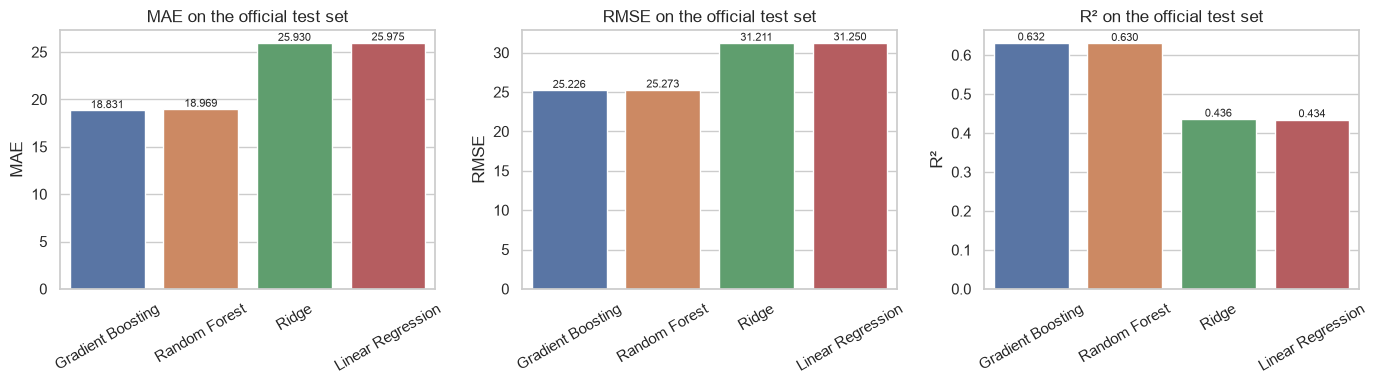

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R²"]):
    sns.barplot(data=test_results_df, x="Model", y=metric, ax=ax, hue="Model", legend=False)
    ax.set_title(f"{metric} on the official test set")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=8)
fig.tight_layout()
fig.savefig(IMAGES / "model_comparison.png", dpi=150)
plt.show()

**Conclusion.** Gradient Boosting is the best model on all three metrics (MAE 18.83 cycles, RMSE 25.23 cycles, R² 0.632). Random Forest is almost tied (MAE 18.97, RMSE 25.27, R² 0.630): a difference of 0.14 cycles in MAE is not meaningful with only 100 test engines, so we choose Gradient Boosting because it also won in cross-validation. Both tree models reduce RMSE by about 19% compared with Linear Regression (31.25). The R² here is lower than in cross-validation even though the errors in cycles are smaller, because the test RUL values are less spread out (standard deviation about 42 cycles), and R² compares the error to that spread.

## 8. Actual vs predicted, and what the model relies on

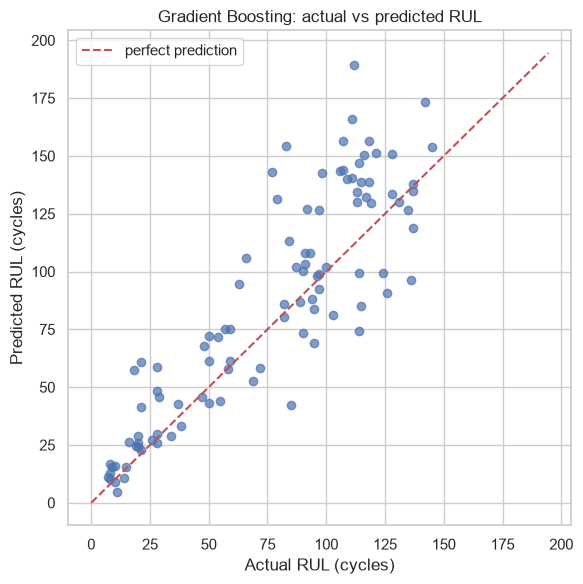

Mean error (bias): 10.5 cycles
Late predictions (model overestimates RUL): 69 of 100 engines


In [9]:
best_name = test_results_df.loc[0, "Model"]
pred = test_predictions[best_name]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, pred, alpha=0.7)
lim = [0, max(y_test.max(), pred.max()) + 5]
ax.plot(lim, lim, "r--", label="perfect prediction")
ax.set_xlabel("Actual RUL (cycles)")
ax.set_ylabel("Predicted RUL (cycles)")
ax.set_title(f"{best_name}: actual vs predicted RUL")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES / "actual_vs_predicted.png", dpi=150)
plt.show()

errors = pred - y_test
print(f"Mean error (bias): {errors.mean():.1f} cycles")
print(f"Late predictions (model overestimates RUL): {(errors > 0).sum()} of {len(errors)} engines")

**Conclusion.** The predictions follow the diagonal but with clear spread. The model overestimates RUL for 69 of the 100 engines (average error +10.5 cycles). This matters most for engines close to failure: among the 25 engines with an actual RUL of 30 cycles or less, 21 are overestimated, which in a real setting could delay maintenance. The model is a good prototype, not a safety tool.

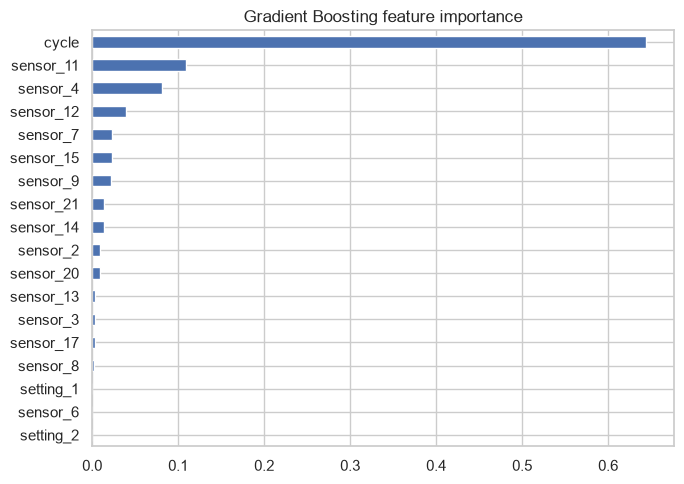

cycle        0.644
sensor_11    0.110
sensor_4     0.081
sensor_12    0.039
sensor_7     0.024
sensor_15    0.023
dtype: float64

In [10]:
gb = final_models["Gradient Boosting"].named_steps["model"]
importance = pd.Series(gb.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
importance.plot.barh(ax=ax)
ax.set_title("Gradient Boosting feature importance")
fig.tight_layout()
fig.savefig(IMAGES / "feature_importance.png", dpi=150)
plt.show()
importance.sort_values(ascending=False).head(6).round(3)

**Conclusion.** `cycle` dominates the model (importance about 0.64), followed by `sensor_11` (0.11), `sensor_4` (0.08) and `sensor_12` (0.04). The operating settings contribute almost nothing, which matches the near-zero correlation found in Notebook 01. The strong reliance on `cycle` works for FD001 (a single operating condition) but may not carry over to engines with other operating conditions.

## 9. Extra experiment: capped RUL
Early in an engine's life the degradation is not visible yet, so predicting "300 cycles left" vs "200 cycles left" is almost impossible. A common practice for C-MAPSS is to cap the target at 125 cycles. Here we test that idea: train on `min(RUL, 125)` and compare against the true RUL capped the same way. This is only an experiment; the saved models and the app use the real (uncapped) RUL.

In [11]:
y_cap = y.clip(upper=RUL_CAP)
y_test_cap = y_test.clip(upper=RUL_CAP)

rows = []
for name in models:
    m = clone(final_models[name]).fit(X, y_cap)
    rows.append({
        "Model": name,
        "R² (full RUL)": test_results_df.set_index("Model").loc[name, "R²"],
        f"R² (RUL capped at {RUL_CAP})": evaluate(y_test_cap, m.predict(X_test))["R²"],
    })
capped_df = pd.DataFrame(rows).sort_values(f"R² (RUL capped at {RUL_CAP})", ascending=False).reset_index(drop=True)
capped_df.round(3)

,Model,R² (full RUL),R² (RUL capped at 125)
0,Gradient Boosting,0.632,0.837
1,Random Forest,0.630,0.824
2,Ridge,0.436,0.714
3,Linear Regression,0.434,0.714


**Conclusion.** Capping the target at 125 cycles raises R² for every model (Gradient Boosting 0.632 → 0.837), because the model no longer has to guess the very large RUL values of healthy engines. These numbers are **not directly comparable** with the main results, since the true target was capped too, which makes the task easier. We report it as an idea for future improvement and keep the real RUL for the saved models and the app.

## 10. Save the models and results

In [12]:
for name, model in final_models.items():
    joblib.dump(model, MODELS_DIR / MODEL_FILES[name])        # pipeline = preprocessing + model

with open(MODELS_DIR / "feature_columns.json", "w") as f:
    json.dump(X.columns.tolist(), f, indent=2)

test_results_df.to_csv(MODELS_DIR / "test_results.csv", index=False)
cv_df.to_csv(MODELS_DIR / "cv_results.csv", index=False)
pd.DataFrame({"actual": y_test, **{n: p for n, p in test_predictions.items()}}).to_csv(
    MODELS_DIR / "test_predictions.csv", index=False)

print("Saved:", sorted(p.name for p in MODELS_DIR.iterdir()))

Saved: ['cv_results.csv', 'feature_columns.json', 'gradient_boosting.joblib', 'linear_regression.joblib', 'random_forest.joblib', 'ridge.joblib', 'test_predictions.csv', 'test_results.csv']


In [13]:
# Sanity check: reload every saved model from disk and confirm it reproduces the test predictions
for name, fname in MODEL_FILES.items():
    loaded = joblib.load(MODELS_DIR / fname)
    assert np.allclose(loaded.predict(X_test), test_predictions[name])
print("All saved models reload correctly and reproduce their predictions.")

All saved models reload correctly and reproduce their predictions.


**Final decision.** Gradient Boosting (tuned) is the selected model: lowest MAE and RMSE and highest R² on the official test set, and also best in cross-validation. All four models are saved as complete pipelines in `Models/` together with `feature_columns.json`, so the Streamlit app can load them and receive raw feature values without any extra preprocessing step.